In [32]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [33]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [34]:
print(x_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000,)


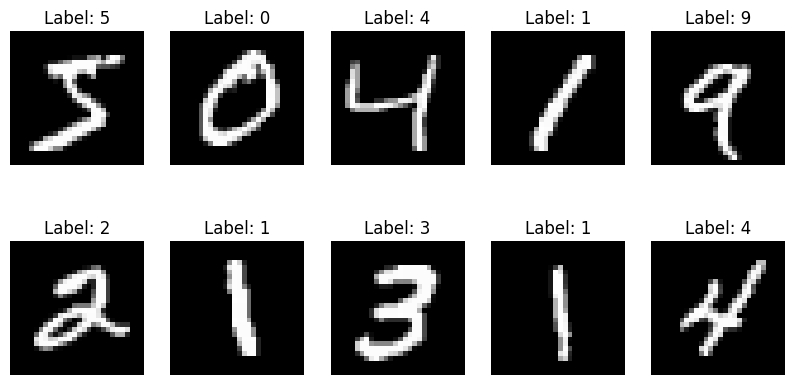

In [35]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [36]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [37]:
model = keras.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),

    layers.Dense(10, activation='softmax')
])

In [38]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=320,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8631 - loss: 0.5057 - val_accuracy: 0.9328 - val_loss: 0.2314
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9413 - loss: 0.2032 - val_accuracy: 0.9524 - val_loss: 0.1698
Epoch 3/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9576 - loss: 0.1483 - val_accuracy: 0.9596 - val_loss: 0.1401
Epoch 4/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9658 - loss: 0.1192 - val_accuracy: 0.9651 - val_loss: 0.1237
Epoch 5/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9720 - loss: 0.0968 - val_accuracy: 0.9668 - val_loss: 0.1133
Epoch 6/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9765 - loss: 0.0811 - val_accuracy: 0.9681 - val_loss: 0.1081
Epoch 7/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9801 - loss: 0.0691 - val_accuracy: 0.9679 - val_loss: 0.1056
Epoch 8/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9826 - loss: 0.0611 - val_accuracy: 0

In [40]:
test_loss ,test_accuray = model.evaluate(x_test, y_test)

print(test_loss)
print(test_accuray)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9765 - loss: 0.0921
0.0920562595129013
0.9764999747276306


In [41]:
y_pred_prod = model.predict(x_test)
y_pred = np.argmax(y_pred_prod, axis=1)

print('actual : ',y_test[:10])
print('predicted : ',y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
actual :  [7 2 1 0 4 1 4 9 5 9]
predicted :  [7 2 1 0 4 1 4 9 6 9]
